[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cleberfmodesto/regressao-xgboost-alura/blob/main/Aulas/Aula_2.ipynb)

#**Aula 1: Obtendo os dados**

##**Importando os dados**

In [18]:
import pandas as pd

In [19]:
url = 'https://raw.githubusercontent.com/cleberfmodesto/regressao-xgboost-alura/main/Dados/dados_automoveis.csv'

In [20]:
df = pd.read_csv(url)

In [21]:
df.head()

,Marca,Modelo,Ano,Tipo_combustivel,Potencia_motor,Cilindros_motor,Tipo_transmissao,Rodas_motrizes,Numero_portas,Tamanho,Estilo,Consumo_estrada_milhas,Consumo_cidade_milhas,Valor($)
0,GMC,Envoy XL,2005,gasolina comum,275.0,6.0,automatico,tracao traseira,4.0,grande,SUV 4 portas,18,13,29695
1,Volkswagen,Passat,2016,gasolina comum,170.0,4.0,automatico,tracao dianteira,4.0,medio,seda,38,25,30495
2,Honda,Odyssey,2016,gasolina comum,248.0,6.0,automatico,tracao dianteira,4.0,grande,minivan de passageiros,28,19,37650
3,Chevrolet,Cruze,2015,gasolina comum,138.0,4.0,manual,tracao dianteira,4.0,medio,seda,36,25,16170
4,Volvo,740,1991,gasolina comum,162.0,4.0,automatico,tracao traseira,4.0,medio,seda,20,17,2000


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10918 entries, 0 to 10917
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Marca                   10918 non-null  object 
 1   Modelo                  10918 non-null  object 
 2   Ano                     10918 non-null  int64  
 3   Tipo_combustivel        10918 non-null  object 
 4   Potencia_motor          10862 non-null  float64
 5   Cilindros_motor         10888 non-null  float64
 6   Tipo_transmissao        10918 non-null  object 
 7   Rodas_motrizes          10918 non-null  object 
 8   Numero_portas           10916 non-null  float64
 9   Tamanho                 10918 non-null  object 
 10  Estilo                  10918 non-null  object 
 11  Consumo_estrada_milhas  10918 non-null  int64  
 12  Consumo_cidade_milhas   10918 non-null  int64  
 13  Valor($)                10918 non-null  int64  
dtypes: float64(3), int64(4), object(7)
mem

##**Processando os dados**

In [23]:
df.duplicated().sum()

np.int64(709)

In [24]:
dados_limpos = df.drop_duplicates()
dados_limpos.reset_index(drop=True, inplace=True)

In [25]:
dados_limpos.shape

(10209, 14)

In [26]:
df_final = dados_limpos.copy()

object_columns = df_final.select_dtypes(include='object').columns
df_final[object_columns] = df_final[object_columns].astype('category')

In [27]:
df_final.dtypes

Marca                     category
Modelo                    category
Ano                          int64
Tipo_combustivel          category
Potencia_motor             float64
Cilindros_motor            float64
Tipo_transmissao          category
Rodas_motrizes            category
Numero_portas              float64
Tamanho                   category
Estilo                    category
Consumo_estrada_milhas       int64
Consumo_cidade_milhas        int64
Valor($)                     int64
dtype: object

#**Aula 2: Utilizando o XGBoost**

##**Separando os dados em treino e teste**

In [28]:
X = df_final.drop(['Valor($)'], axis=1)
y = df_final['Valor($)']

In [29]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=4256)

##**Realizando previsões com a API do Scikit-Learn**

In [30]:
import xgboost as xgb

In [31]:
xgb.__version__

'3.2.0'

In [32]:
modelo = xgb.XGBRegressor(objective='reg:squarederror', enable_categorical=True, n_estimators=100)

modelo.fit(X_treino, y_treino)
preds = modelo.predict(X_teste)

##**Obtendo métricas de desempenho**

In [33]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_teste, preds)
print(f'MSE: {mse:.2f}')

MSE: 10073067.00


In [34]:
rmse = mean_squared_error(y_teste, preds) ** 0.5
print(f'RMSE: {rmse:.2f}')

RMSE: 3173.81


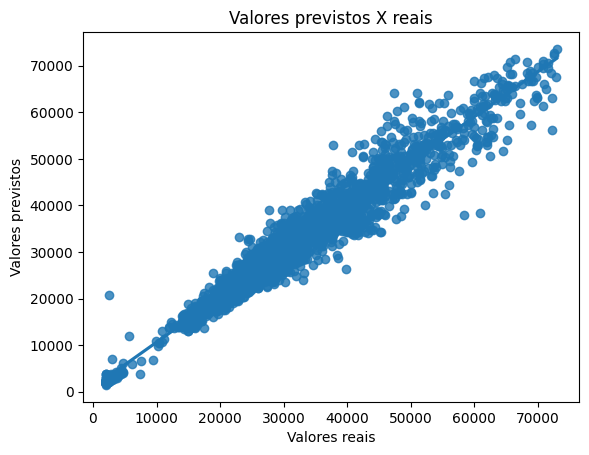

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.regplot(x=y_teste, y=preds)
plt.xlabel('Valores reais')
plt.ylabel('Valores previstos')
plt.title('Valores previstos X reais')
plt.show()

##**Realizando previsões com a API nativa do XGBoost**

In [36]:
dtreino = xgb.DMatrix(X_treino, y_treino, enable_categorical=True)
dteste = xgb.DMatrix(X_teste, y_teste, enable_categorical=True)

In [37]:
params = {'objective': 'reg:squarederror'}

modelo = xgb.train(
    params=params,
    dtrain=dtreino,
    num_boost_round=100
)

preds = modelo.predict(dteste)

In [38]:
rmse = mean_squared_error(dteste.get_label(), preds) ** 0.5
print(f'RMSE: {rmse:.2f}')

RMSE: 3173.81


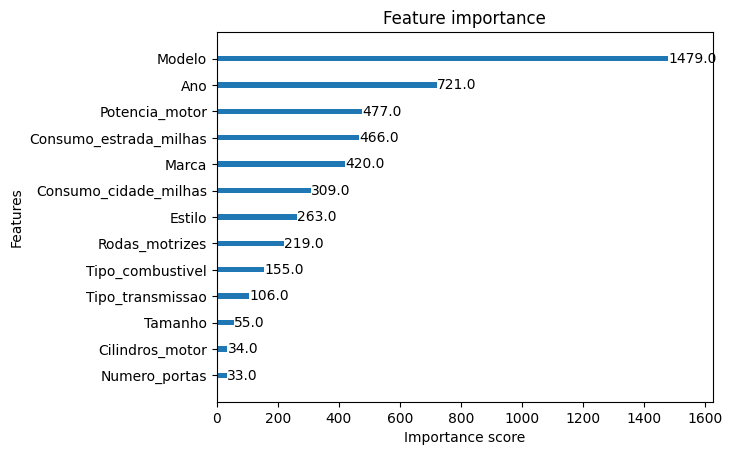

In [39]:
xgb.plot_importance(modelo)
plt.grid(False)
plt.show()